# 07 — Графики для отчёта

Этот ноутбук **ничего не исследует и не подбирает**. Он только рисует графики по уже сделанным экспериментам:

- из журнала `reports/research_log_year1.csv` (все прогоны ноутбука 05);
- из пересчёта сделок v1 и v2 на году 1 (причины выходов, кварталы, худшие сделки);
- β и half-life по кварталам года 1.

Все картинки сохраняются в `reports/figures/07_*.png` и вставлены в README.

**Перед запуском:** в ноутбуке 05 ячейка сохранения CSV должна быть **последней** и выполненной после всех экспериментов
(иначе в журнале не будет 4.5 и 4.6).

## 1. Setup и журнал

Проверка: для каждого эксперимента в журнале должно быть больше 0 вариантов.
Если где-то 0 — пересохрани CSV в ноутбуке 05.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent                 # notebooks/ → корень проекта
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import datetime, timezone
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

import config
from src.funding import load_funding, funding_on_bars
from src.signals import log_spread, rolling_zscore
from src.engine_numba import run_backtest_fast

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

log = (pl.read_csv(ROOT / "reports" / "research_log_year1.csv")
         .unique(subset=["name", "tier"], keep="first", maintain_order=True))   # без дублей
vip = log.filter(pl.col("tier") == "vip7")                                      # графики по VIP-7
base = vip.filter(pl.col("name") == "baseline")["sharpe"][0]                    # v1 на году 1

print("запусков в журнале:", log.height, "| baseline Sharpe:", round(base, 2))   # ожидаем −1.76
for prefix in ("loss", "max_hold", "grid", "hold", "beta", "exit"):
    n = vip.filter(pl.col("name").str.starts_with(prefix)).height
    print(f"{prefix:9s}: {n} вариантов")

запусков в журнале: 162 | baseline Sharpe: -1.76
loss     : 10 вариантов
max_hold : 5 вариантов
grid     : 28 вариантов
hold     : 24 вариантов
beta     : 8 вариантов
exit     : 5 вариантов


## 2. Данные года 1 и сделки v1 / v2

Тот же расчёт, что в ноутбуках 05 и 06. Проверка: v1 = 483 сделки, −6 931; v2 = 74 сделки, −1 627.

In [2]:
df = pl.read_parquet(config.PROCESSED_DIR / "pair_5m.parquet")
open_time = df["open_time"].to_numpy()
fa = funding_on_bars(open_time, load_funding(config.SYMBOL_A))     # фандинг ETH на каждой свече
fb = funding_on_bars(open_time, load_funding(config.SYMBOL_B))     # фандинг BTC на каждой свече

oos = datetime.fromisoformat(config.OOS_START).replace(tzinfo=timezone.utc)
split = int((df["open_time"] < int(oos.timestamp() * 1000)).sum())  # первая свеча года 2
cut = slice(0, split)                                               # год 1

open_a, open_b = df["open_a"].to_numpy(), df["open_b"].to_numpy()
close_a, close_b = df["close_a"].to_numpy(), df["close_b"].to_numpy()
tradable = ((df["n_traded_a"] > 0) & (df["n_traded_b"] > 0)).to_numpy()
spread = log_spread(close_a, close_b)                               # β = 1

t1 = pl.from_epoch(df["open_time"][cut], time_unit="ms")
quarter = (t1.dt.year().cast(pl.Utf8) + "-Q" + t1.dt.quarter().cast(pl.Utf8)).to_numpy()   # квартал каждой свечи
QUARTERS = sorted(set(quarter))


def run_y1(window, entry_z):
    """Прогон на году 1 (VIP-7) → результат движка и таблица сделок."""
    z = rolling_zscore(spread, window)
    r = run_backtest_fast(open_a[cut], open_b[cut], close_a[cut], close_b[cut],
                          tradable[cut], z[cut], "vip7", fa[cut], fb[cut], entry_z=entry_z)
    return r, pl.DataFrame(r["trades"])


r1, tr1 = run_y1(config.WINDOW, config.ENTRY_Z)          # v1
r2, tr2 = run_y1(config.V2_WINDOW, config.V2_ENTRY_Z)    # v2
print("v1:", tr1.height, "сделок, итог", round(tr1["pnl"].sum()))
print("v2:", tr2.height, "сделок, итог", round(tr2["pnl"].sum()))

v1: 483 сделок, итог -6931
v2: 74 сделок, итог -1627


## 3. v1: весь убыток — от нескольких сделок (диагностика 4.4)

Слева: 10 худших сделок против всех остальных. Справа: распределение PnL сделок — типичная сделка в плюсе,
но длинный левый хвост.

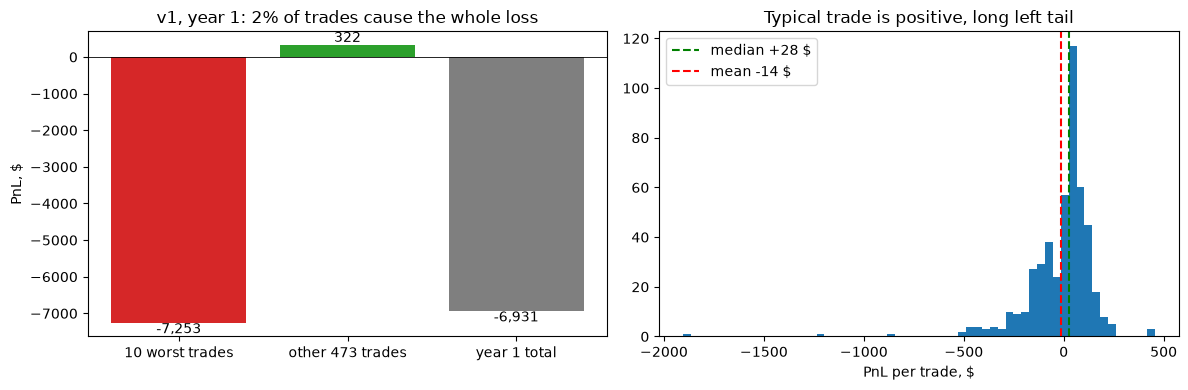

In [3]:
pnl = np.sort(tr1["pnl"].to_numpy())
parts = {"10 worst trades": pnl[:10].sum(),
         f"other {len(pnl) - 10} trades": pnl[10:].sum(),
         "year 1 total": pnl.sum()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

bars = ax1.bar(parts.keys(), parts.values(), color=["tab:red", "tab:green", "tab:gray"])
for b, v in zip(bars, parts.values()):
    ax1.text(b.get_x() + b.get_width() / 2, v, f"{v:,.0f}", ha="center", va="bottom" if v > 0 else "top")
ax1.axhline(0, color="black", lw=0.6)
ax1.set_ylabel("PnL, $")
ax1.set_title("v1, year 1: 2% of trades cause the whole loss")

ax2.hist(pnl, bins=60, color="tab:blue")
ax2.axvline(np.median(pnl), color="green", ls="--", label=f"median {np.median(pnl):+.0f} $")
ax2.axvline(pnl.mean(), color="red", ls="--", label=f"mean {pnl.mean():+.0f} $")
ax2.set_xlabel("PnL per trade, $")
ax2.set_title("Typical trade is positive, long left tail")
ax2.legend()

plt.tight_layout()
plt.savefig(FIG / "07_worst_trades.png", dpi=150)
plt.show()

## 4. Эксперимент 4.1 — стоп по убытку сделки

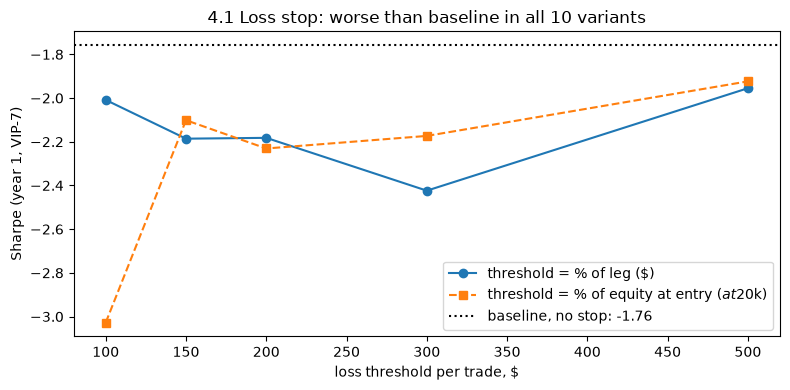

In [4]:
leg = vip.filter(pl.col("name").str.contains("of leg")).sort("max_loss")
eqp = vip.filter(pl.col("name").str.contains("of equity")).sort("max_loss_pct")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(leg["max_loss"], leg["sharpe"], "o-", label="threshold = % of leg ($)")
ax.plot(eqp["max_loss_pct"] * config.CAPITAL, eqp["sharpe"], "s--",
        label="threshold = % of equity at entry ($ at $20k)")
ax.axhline(base, color="black", ls=":", label=f"baseline, no stop: {base:.2f}")
ax.set_xlabel("loss threshold per trade, $")
ax.set_ylabel("Sharpe (year 1, VIP-7)")
ax.set_title("4.1 Loss stop: worse than baseline in all 10 variants")
ax.legend()

plt.tight_layout()
plt.savefig(FIG / "07_loss_stop.png", dpi=150)
plt.show()

## 5. Эксперимент 4.2 — короче time-стоп

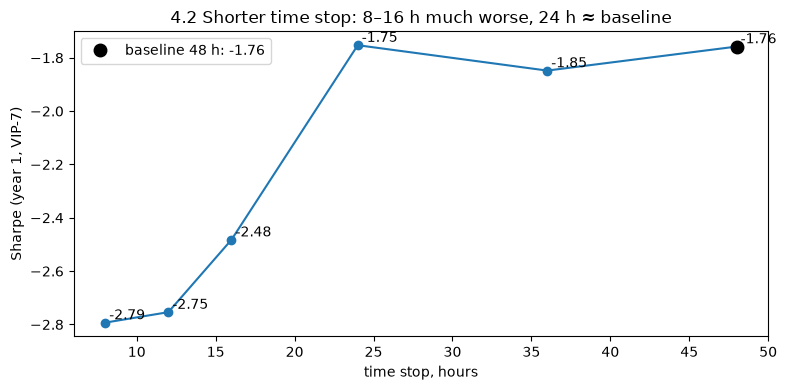

In [5]:
mh = vip.filter(pl.col("name").str.starts_with("max_hold")).sort("max_hold")
hours = list(mh["max_hold"].to_numpy() * 5 / 60) + [48]       # + baseline: 576 свечей = 48 ч
sharpe = list(mh["sharpe"]) + [base]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hours, sharpe, "o-")
ax.plot(48, base, "o", color="black", ms=9, label=f"baseline 48 h: {base:.2f}")
for h, s in zip(hours, sharpe):
    ax.text(h, s, f" {s:.2f}", va="bottom")
ax.set_xlabel("time stop, hours")
ax.set_ylabel("Sharpe (year 1, VIP-7)")
ax.set_title("4.2 Shorter time stop: 8–16 h much worse, 24 h ≈ baseline")
ax.legend()

plt.tight_layout()
plt.savefig(FIG / "07_time_stop.png", dpi=150)
plt.show()

## 6. Почему v2 лучше — причины выходов (год 1)

Сумма PnL по причине выхода, n — число сделок.

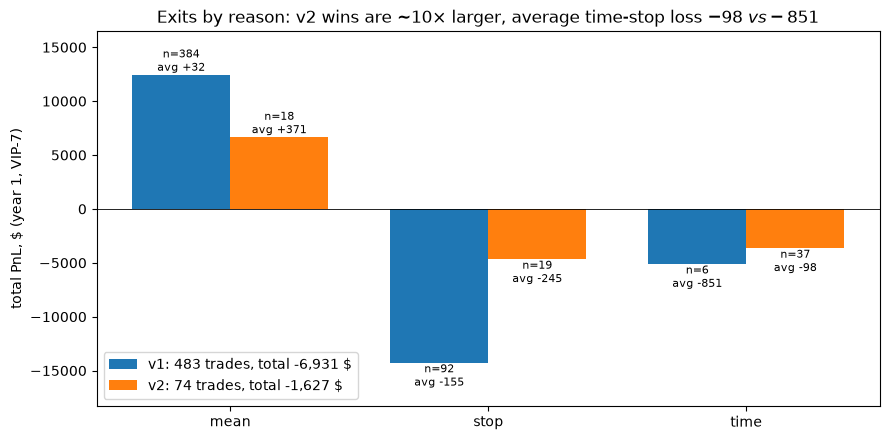

In [12]:
REASONS = ["mean", "stop", "time"]

fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (name, tr) in enumerate((("v1", tr1), ("v2", tr2))):
    g = tr.group_by("reason").agg(total=pl.col("pnl").sum(), n=pl.len(), avg=pl.col("pnl").mean())
    totals = [g.filter(pl.col("reason") == r)["total"].sum() for r in REASONS]
    counts = [g.filter(pl.col("reason") == r)["n"].sum() for r in REASONS]
    avgs = [g.filter(pl.col("reason") == r)["avg"].sum() for r in REASONS]   # средний PnL сделки
    bars = ax.bar(np.arange(3) + (k - 0.5) * 0.38, totals, 0.38,
                  label=f"{name}: {tr.height} trades, total {tr['pnl'].sum():,.0f} $")
    for b, n, a in zip(bars, counts, avgs):
        h = b.get_height()
        ax.text(b.get_x() + b.get_width() / 2, h, f"n={n}\navg {a:+,.0f}",
                ha="center", va="bottom" if h > 0 else "top", fontsize=8)

ax.set_xticks(np.arange(3), REASONS)
ax.axhline(0, color="black", lw=0.6)
ax.margins(y=0.15)                                   # запас для подписей
ax.set_ylabel("total PnL, $ (year 1, VIP-7)")
ax.set_title("Exits by reason: v2 wins are ~10× larger, average time-stop loss −98 $ vs −851 $")
ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig(FIG / "07_exit_reasons.png", dpi=150)
plt.show()

## 7. Эксперимент 4.2b — time-стоп для длинных окон

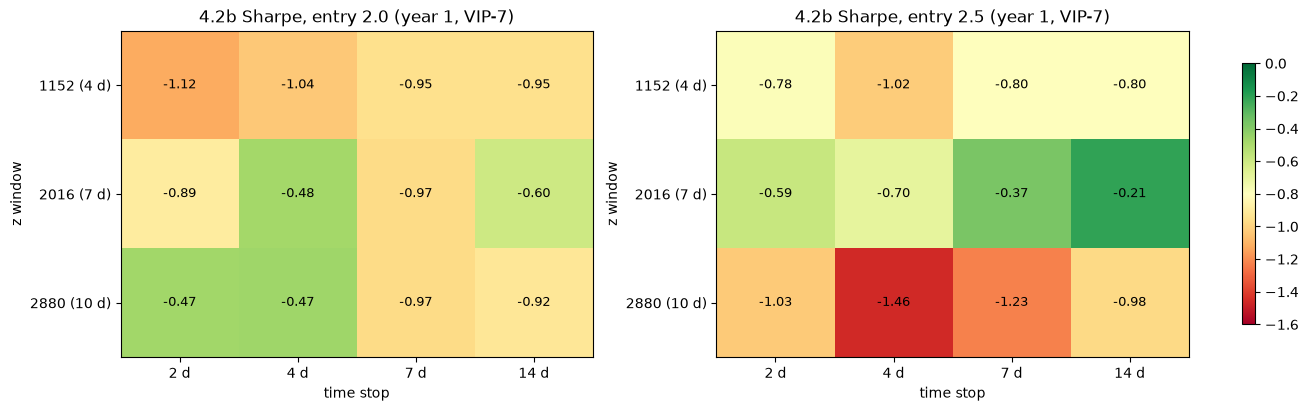

In [7]:
hold = vip.filter(pl.col("name").str.starts_with("hold"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)   # без наложения подписей
for ax, e in zip(axes, (2.0, 2.5)):
    t = (hold.filter(pl.col("entry_z") == e)
             .pivot(on="max_hold", index="window", values="sharpe")
             .sort("window"))
    cols = sorted([c for c in t.columns if c != "window"], key=float)   # time-стопы по возрастанию
    vals = t.select(cols).to_numpy()

    im = ax.imshow(vals, cmap="RdYlGn", aspect="auto", vmin=-1.6, vmax=0)
    ax.set_xticks(range(len(cols)), [f"{int(c) * 5 / 60 / 24:.0f} d" for c in cols])
    ax.set_yticks(range(t.height), [f"{w} ({w * 5 / 60 / 24:.0f} d)" for w in t["window"]])
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            ax.text(j, i, f"{vals[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_xlabel("time stop")
    ax.set_ylabel("z window")
    ax.set_title(f"4.2b Sharpe, entry {e} (year 1, VIP-7)")

fig.colorbar(im, ax=axes, shrink=0.8)
plt.savefig(FIG / "07_hold_grid.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. β и half-life по кварталам (год 1)

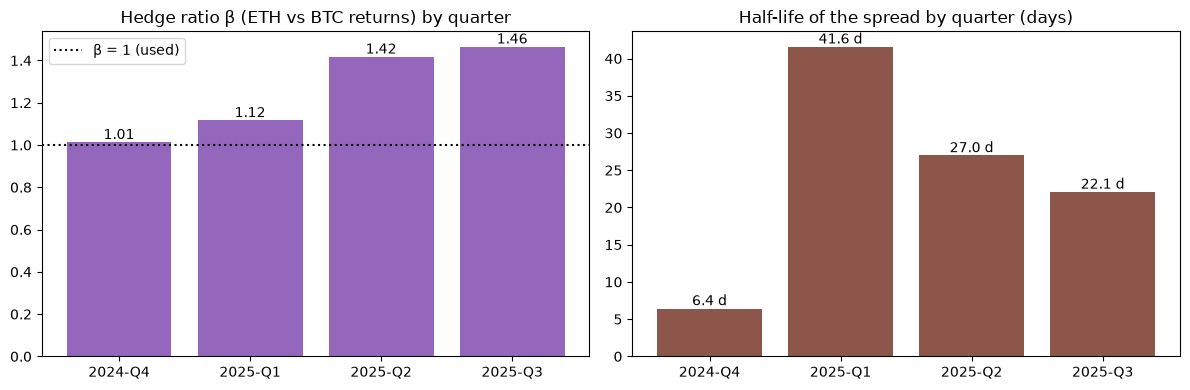

In [8]:
ra = np.diff(np.log(close_a[cut]))                   # 5-минутные доходности ETH
rb = np.diff(np.log(close_b[cut]))                   # 5-минутные доходности BTC
q_ret = quarter[1:]                                  # квартал каждой доходности
betas = [np.cov(ra[q_ret == q], rb[q_ret == q])[0, 1] / np.var(rb[q_ret == q], ddof=1) for q in QUARTERS]

s1 = spread[cut]


def half_life_days(s):
    """Half-life спреда в днях: регрессия Δs_t = a + b·s_(t−1)."""
    b = np.polyfit(s[:-1], np.diff(s), 1)[0]
    return np.inf if b >= 0 else -np.log(2) / np.log(1 + b) / 288


hls = [half_life_days(s1[quarter == q]) for q in QUARTERS]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

bars = ax1.bar(QUARTERS, betas, color="tab:purple")
ax1.axhline(1, color="black", ls=":", label="β = 1 (used)")
for b, v in zip(bars, betas):
    ax1.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom")
ax1.set_title("Hedge ratio β (ETH vs BTC returns) by quarter")
ax1.legend()

bars = ax2.bar(QUARTERS, hls, color="tab:brown")
for b, v in zip(bars, hls):
    ax2.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f} d", ha="center", va="bottom")
ax2.set_title("Half-life of the spread by quarter (days)")

plt.tight_layout()
plt.savefig(FIG / "07_beta_halflife.png", dpi=150)
plt.show()

## 9. Эксперимент 4.5 — скользящий β

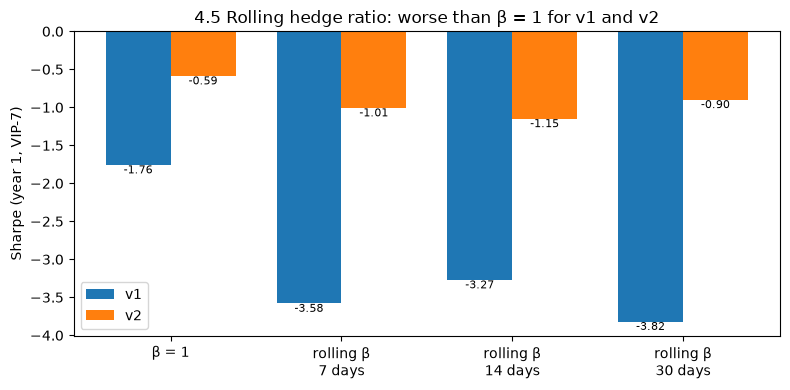

In [9]:
bt = vip.filter(pl.col("name").str.starts_with("beta"))
LABELS = {0: "β = 1", 2016: "rolling β\n7 days", 4032: "rolling β\n14 days", 8640: "rolling β\n30 days"}
x = np.arange(len(LABELS))

fig, ax = plt.subplots(figsize=(8, 4))
for k, v in enumerate(("v1", "v2")):
    sub = bt.filter(pl.col("name").str.starts_with(f"beta {v} ")).sort("beta_window")
    bars = ax.bar(x + (k - 0.5) * 0.38, sub["sharpe"], 0.38, label=v)
    for b, s in zip(bars, sub["sharpe"]):
        ax.text(b.get_x() + b.get_width() / 2, s, f"{s:.2f}", ha="center", va="top", fontsize=8)

ax.set_xticks(x, LABELS.values())
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("Sharpe (year 1, VIP-7)")
ax.set_title("4.5 Rolling hedge ratio: worse than β = 1 for v1 and v2")
ax.legend()

plt.tight_layout()
plt.savefig(FIG / "07_beta.png", dpi=150)
plt.show()

## 10. Проверка v2 по кварталам (год 1)

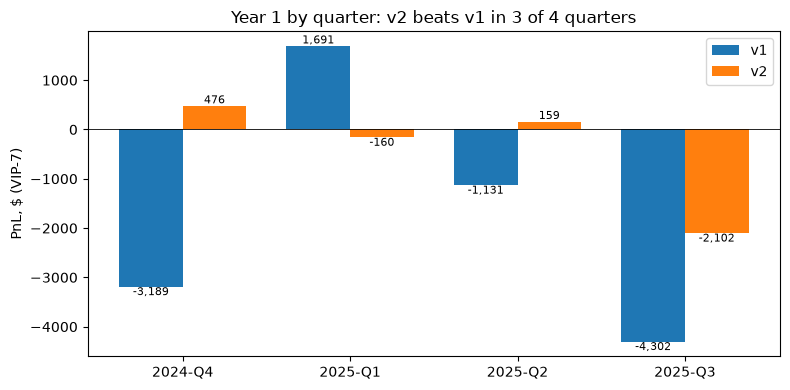

In [10]:
def quarterly_pnl(r):
    """PnL по кварталам года 1 из кривой капитала."""
    pnl_bar = np.diff(np.concatenate([[config.CAPITAL], r["equity"]]))   # изменение капитала на свече
    return [pnl_bar[quarter == q].sum() for q in QUARTERS]


fig, ax = plt.subplots(figsize=(8, 4))
for k, (name, r) in enumerate((("v1", r1), ("v2", r2))):
    vals = quarterly_pnl(r)
    bars = ax.bar(np.arange(len(QUARTERS)) + (k - 0.5) * 0.38, vals, 0.38, label=name)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.0f}", ha="center",
                va="bottom" if v > 0 else "top", fontsize=8)

ax.set_xticks(np.arange(len(QUARTERS)), QUARTERS)
ax.axhline(0, color="black", lw=0.6)
ax.set_ylabel("PnL, $ (VIP-7)")
ax.set_title("Year 1 by quarter: v2 beats v1 in 3 of 4 quarters")
ax.legend()

plt.tight_layout()
plt.savefig(FIG / "07_quarters.png", dpi=150)
plt.show()

## 11. Эксперимент 4.6 — выход раньше нуля (exit_z)

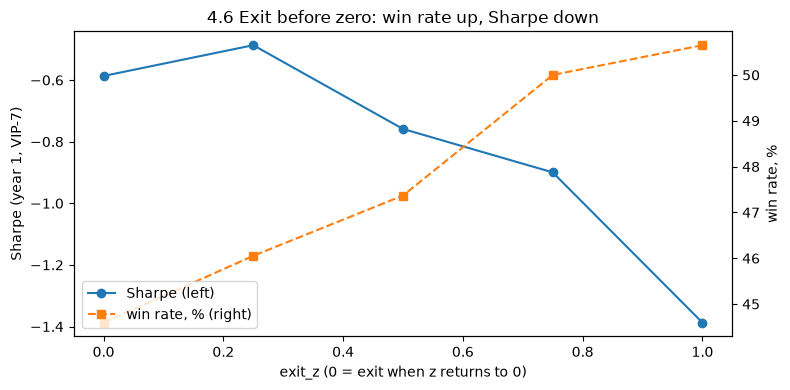

In [11]:
ex = vip.filter(pl.col("name").str.starts_with("exit")).sort("exit_z")

fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()                                    # вторая ось Y справа
ax1.plot(ex["exit_z"], ex["sharpe"], "o-", color="tab:blue", label="Sharpe (left)")
ax2.plot(ex["exit_z"], ex["win_rate"] * 100, "s--", color="tab:orange", label="win rate, % (right)")
ax1.set_xlabel("exit_z (0 = exit when z returns to 0)")
ax1.set_ylabel("Sharpe (year 1, VIP-7)")
ax2.set_ylabel("win rate, %")
ax1.set_title("4.6 Exit before zero: win rate up, Sharpe down")
fig.legend(loc="lower left", bbox_to_anchor=(0.1, 0.15))

plt.tight_layout()
plt.savefig(FIG / "07_exit_z.png", dpi=150)
plt.show()

## Готово

В `reports/figures/` должны появиться:
`07_worst_trades.png`, `07_loss_stop.png`, `07_time_stop.png`, `07_exit_reasons.png`, `07_hold_grid.png`,
`07_beta_halflife.png`, `07_beta.png`, `07_quarters.png`, `07_exit_z.png`.